## Đọc dữ liệu

In [3]:
# Nạp thư viện os (Operating System) — dùng để tương tác với hệ điều hành (ví dụ: quản lý tệp tin, nối đường dẫn thư mục, kiểm tra tệp tồn tại).
import os
# Nạp thư viện numpy và đặt tên viết tắt là np — dùng để xử lý tính toán đại số tuyến tính, mảng nhiều chiều (array) và các phép toán số học tốc độ cao.
import numpy as np
# Nạp thư viện pandas và đặt tên viết tắt là pd — dùng để làm việc với dữ liệu dạng bảng (DataFrame), hỗ trợ đọc/ghi tệp CSV, Excel và tiền xử lý dữ liệu
import pandas as pd

# Ghép đường dẫn giữa thư mục 'path' (từ kagglehub) và tên tệp CSV
file_path = os.path.join(
    "..", "..", "data", "raw", "Diamonds Prices2022.csv"
)

# Đọc tệp CSV vào biến 'diamonds' (DataFrame) với dấu phân cách các cột là dấu phẩy (,)
diamonds = pd.read_csv(file_path, sep=',', index_col=0)

# In kích thước của tập dữ liệu (số dòng, số cột)
print(f"Kích thước tập dữ liệu ban đầu: {diamonds.shape}\n")

# Hiển thị thông tin tổng quan
diamonds.info()

# In tiêu đề thông báo cho phần hiển thị 5 dòng đầu
print("\n--- 5 dòng đầu tiên ---")
# Hiển thị 5 dòng dữ liệu đầu tiên
print(diamonds.head())

# In tiêu đề thông báo cho phần kiểm tra các giá trị phân loại
print("\n--- Giá trị phân loại của các thuộc tính dạng chuỗi ---")
# Lấy và in danh sách các giá trị duy nhất (không trùng lặp) của cột 'cut' (vết cắt)
print(f"Cut: {diamonds['cut'].unique()}")
# Lấy và in danh sách các giá trị duy nhất của cột 'color' (màu sắc)
print(f"Color: {diamonds['color'].unique()}")
# Lấy và in danh sách các giá trị duy nhất của cột 'clarity' (độ tinh khiết)
print(f"Clarity: {diamonds['clarity'].unique()}")

# In tiêu đề thông báo cho phần thống kê mô tả
print("\n--- Thống kê mô tả ---")
# Tính toán các chỉ số thống kê cơ bản cho các cột số
print(diamonds.describe())

Kích thước tập dữ liệu ban đầu: (53943, 10)

<class 'pandas.DataFrame'>
RangeIndex: 53943 entries, 1 to 53943
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   carat    53943 non-null  float64
 1   cut      53943 non-null  str    
 2   color    53943 non-null  str    
 3   clarity  53943 non-null  str    
 4   depth    53943 non-null  float64
 5   table    53943 non-null  float64
 6   price    53943 non-null  int64  
 7   x        53943 non-null  float64
 8   y        53943 non-null  float64
 9   z        53943 non-null  float64
dtypes: float64(6), int64(1), str(3)
memory usage: 4.1 MB

--- 5 dòng đầu tiên ---
   carat      cut color clarity  depth  table  price     x     y     z
1   0.23    Ideal     E     SI2   61.5   55.0    326  3.95  3.98  2.43
2   0.21  Premium     E     SI1   59.8   61.0    326  3.89  3.84  2.31
3   0.23     Good     E     VS1   56.9   65.0    327  4.05  4.07  2.31
4   0.29  Premium     I     VS2   

## Tiền xử lý dữ liệu

In [7]:
# Nạp công cụ OrdinalEncoder từ thư viện scikit-learn để mã hóa các biến phân loại có thứ tự
from sklearn.preprocessing import OrdinalEncoder

# 1: Loại bỏ thuộc tính không mang thông tin
# Kiểm tra xem cột số thứ tự thừa 'Unnamed: 0' có tồn tại trong DataFrame hay không
if 'Unnamed: 0' in diamonds.columns:
    # Nếu có, xóa bỏ cột này khỏi tập dữ liệu
    diamonds = diamonds.drop(columns=['Unnamed: 0'])

# 2: Mã hóa thứ tự (Ordinal Encoding) cho các thuộc tính phân loại
# Định nghĩa danh sách các mức độ chất lượng của vết cắt 'cut' theo thứ tự tăng dần (Fair là thấp nhất, Ideal là cao nhất)
cut_categories = ['Fair', 'Good', 'Very Good', 'Premium', 'Ideal']

# Định nghĩa danh sách màu sắc 'color' theo thứ tự tăng dần từ kém nhất đến tốt nhất (J -> D)
color_categories = ['J', 'I', 'H', 'G', 'F', 'E', 'D']

# Định nghĩa danh sách độ tinh khiết 'clarity' theo thứ tự tăng dần từ kém nhất đến tốt nhất (I1 -> IF)
clarity_categories = ['I1', 'SI2', 'SI1', 'VS2', 'VS1', 'VVS2', 'VVS1', 'IF']

# Khởi tạo đối tượng OrdinalEncoder với danh sách thứ tự đã thiết lập cho từng cột
encoder = OrdinalEncoder(categories=[cut_categories, color_categories, clarity_categories])

# chuyển đổi các cột dữ liệu dạng chữ (phân loại) thành dạng số dựa trên thứ tự đã định nghĩa
diamonds[['cut', 'color', 'clarity']] = encoder.fit_transform(diamonds[['cut', 'color', 'clarity']])

# 3: Kiểm tra dữ liệu sau tiền xử lý
# In kích thước mới của tập dữ liệu (số dòng, số cột) sau khi đã làm sạch và chuyển đổi
print(f"\nKích thước tập dữ liệu sau tiền xử lý: {diamonds.shape}\n")

# In tiêu đề thông báo hiển thị 5 dòng đầu
print("--- 5 dòng dữ liệu đầu sau tiền xử lý ---")

# Hiển thị 5 dòng dữ liệu đầu tiên sau tiền xử lý
print(diamonds.head())


Kích thước tập dữ liệu sau tiền xử lý: (53943, 10)

--- 5 dòng dữ liệu đầu sau tiền xử lý ---
   carat  cut  color  clarity  depth  table  price     x     y     z
1   0.23  4.0    5.0      1.0   61.5   55.0    326  3.95  3.98  2.43
2   0.21  3.0    5.0      2.0   59.8   61.0    326  3.89  3.84  2.31
3   0.23  1.0    5.0      4.0   56.9   65.0    327  4.05  4.07  2.31
4   0.29  3.0    1.0      3.0   62.4   58.0    334  4.20  4.23  2.63
5   0.31  1.0    0.0      1.0   63.3   58.0    335  4.34  4.35  2.75


## Chia tập dữ liệu

In [8]:
from sklearn.model_selection import train_test_split

# X là dữ liệu các thuộc tính
X = diamonds.drop(columns=["price"])
# y là dữ liệu nhãn
y = diamonds["price"]

# Chia dữ liệu train test
X_train, X_test, y_train, y_test = train_test_split(
      X,
      y,
      test_size=0.2,
      random_state=42
    )

# In ra kết quả chia dữ liệu
print(f"Có {X_train.shape[0]} mẫu huấn luyện và {X_test.shape[0]} mẫu kiểm tra")

Có 43154 mẫu huấn luyện và 10789 mẫu kiểm tra


## Training

KẾT QUẢ ĐÁNH GIÁ TOP 5 MÔ HÌNH - HOLDOUT

Model 1:
Max depth: 12
Min samples leaf: 9
Min samples split: 20
MAE Train: 266.2237
MSE Train: 255721.4176
RMSE Train: 505.6891
R² Train: 0.9840
MAE Test: 305.6556
MSE Test: 350597.7900
RMSE Test: 592.1130
R² Test: 0.9775
Thời gian Train: 0.1070 giây

Model 2:
Max depth: 12
Min samples leaf: 8
Min samples split: 20
MAE Train: 264.7328
MSE Train: 253070.6543
RMSE Train: 503.0613
R² Train: 0.9842
MAE Test: 305.7023
MSE Test: 351140.0955
RMSE Test: 592.5708
R² Test: 0.9775
Thời gian Train: 0.1107 giây

Model 3:
Max depth: 12
Min samples leaf: 8
Min samples split: 19
MAE Train: 263.7429
MSE Train: 251057.5724
RMSE Train: 501.0565
R² Train: 0.9843
MAE Test: 305.6583
MSE Test: 351464.6457
RMSE Test: 592.8445
R² Test: 0.9775
Thời gian Train: 0.1129 giây

Model 4:
Max depth: 12
Min samples leaf: 9
Min samples split: 8
MAE Train: 264.5776
MSE Train: 251942.7861
RMSE Train: 501.9390
R² Train: 0.9842
MAE Test: 306.0425
MSE Test: 352968.6957
RMSE Test: 59

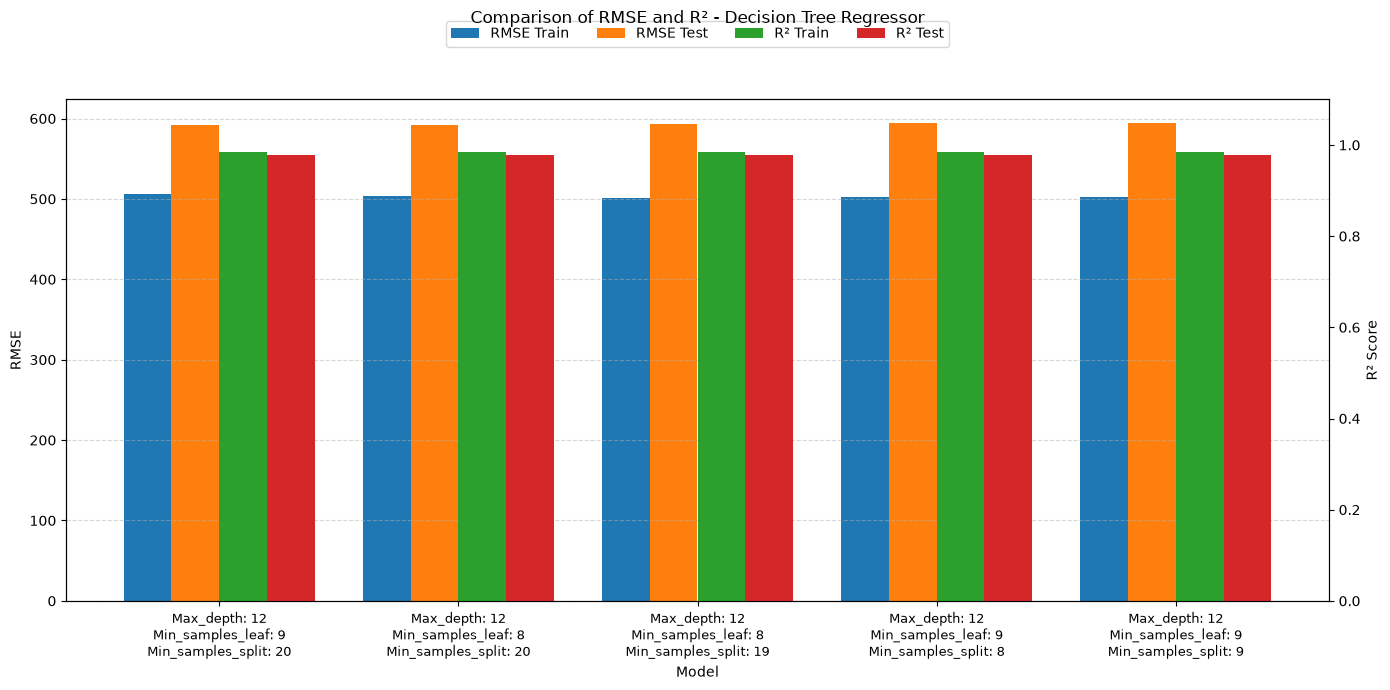

In [10]:
# Import mô hình cây quyết định hồi quy
from sklearn.tree import DecisionTreeRegressor
# Import các hàm đánh giá
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
# Import hàm tính hệ số xác định R²
from sklearn.metrics import r2_score
# Import hàm tính căn bậc hai
from math import sqrt
# Import thư viện đo thời gian
import time
# Import thư viện vẽ biểu đồ
import matplotlib.pyplot as plt
# Import thư viện xử lý mảng
import numpy as np

# Khai báo các giá trị max_depth cần thử (từ 10 đến 20)
max_depth_values = range(10, 21)
# Khai báo các giá trị min_samples_leaf cần thử (từ 2 đến 12)
min_samples_leaf_values = range(2, 13)
# Khai báo các giá trị min_samples_split cần thử (từ 8 đến 20)
min_samples_split_values = range(8, 21)

# Khởi tạo danh sách lưu kết quả của 5 mô hình tốt nhất
top_5_results = []

# Duyệt qua từng giá trị max_depth
for max_depth in max_depth_values:
  # Duyệt qua từng giá trị min_samples_leaf
  for min_samples_leaf in min_samples_leaf_values:
    # Duyệt qua từng giá trị min_samples_split
    for min_samples_split in min_samples_split_values:

      # Khởi tạo mô hình với bộ tham số hiện tại
      model = DecisionTreeRegressor(
        criterion="squared_error",  # Chọn tiêu chí chia nút dựa trên việc giảm tổng sai số bình phương
        random_state=42,  # Cố định giá trị ngẫu nhiên
        max_depth=max_depth,  # Quy định độ sâu tối đa của cây
        min_samples_leaf=min_samples_leaf,  # Quy định số mẫu tối thiểu tại nút lá
        min_samples_split=min_samples_split  # Quy định số mẫu tối thiểu để chia nút
      )

      # Bắt đầu đo thời gian huấn luyện
      start_time = time.perf_counter()

      # Huấn luyện mô hình trên tập Train
      model.fit(X_train, y_train)

      # Tính thời gian huấn luyện
      training_time = time.perf_counter() - start_time

      # Dự đoán trên tập Train
      y_pred_train = model.predict(X_train)
      # Dự đoán trên tập Test
      y_pred_test = model.predict(X_test)
      
      # Tính MAE trên Train
      mae_train = mean_absolute_error(y_train, y_pred_train)
      # Tính MSE trên Train
      mse_train = mean_squared_error(y_train, y_pred_train)
      # Tính RMSE trên Train
      rmse_train = np.sqrt(mse_train)
      # Tính R² trên Train
      r2_train = r2_score(y_train, y_pred_train)

      # Tính MAE trên Test
      mae_test = mean_absolute_error(y_test, y_pred_test)
      # Tính MSE trên Test
      mse_test = mean_squared_error(y_test, y_pred_test)
      # Tính RMSE trên Test
      rmse_test = np.sqrt(mse_test)
      # Tính R² trên Test
      r2_test = r2_score(y_test, y_pred_test)

      # Lưu kết quả của bộ tham số hiện tại
      current_result = {
        'max_depth': max_depth,
        'min_samples_leaf': min_samples_leaf,
        'min_samples_split': min_samples_split,
        'mae_train': mae_train,
        'mse_train': mse_train,
        'rmse_train': rmse_train,
        'r2_train': r2_train,
        'mae_test': mae_test,
        'mse_test': mse_test,
        'rmse_test': rmse_test,
        'r2_test': r2_test,
        'train_time': training_time,
        'model_object': model
      }

      # Thêm kết quả hiện tại vào danh sách
      top_5_results.append(current_result)

      # Sắp xếp danh sách theo RMSE Test tăng dần
      top_5_results = sorted(
        top_5_results,
        key=lambda x: x['rmse_test']
      )
      # Chỉ giữ lại 5 bộ tham số có RMSE Test thấp nhất
      top_5_results = top_5_results[:5]

# Khởi tạo danh sách lưu kết quả đánh giá Top 5
final_results = []

# Duyệt qua từng bộ tham số trong Top 5
for i, result in enumerate(top_5_results, start=1):
  # Lưu kết quả đánh giá của mô hình
  final_results.append({
    'model': f'Model {i}',
    'max_depth': result['max_depth'],
    'min_samples_leaf': result['min_samples_leaf'],
    'min_samples_split': result['min_samples_split'],
    'mae_train': result['mae_train'],
    'mse_train': result['mse_train'],
    'rmse_train': result['rmse_train'],
    'r2_train': result['r2_train'],
    'mae_test': result['mae_test'],
    'mse_test': result['mse_test'],
    'rmse_test': result['rmse_test'],
    'r2_test': result['r2_test'],
    'train_time': result['train_time'],
    'model_object': result['model_object']
  })


# In kết quả đánh giá Top 5 mô hình
print("KẾT QUẢ ĐÁNH GIÁ TOP 5 MÔ HÌNH - HOLDOUT")

# Duyệt qua từng mô hình trong final_results
for result in final_results:

  # In tên mô hình
  print(f"\n{result['model']}:")

  # In bộ tham số tương ứng
  print(f"Max depth: {result['max_depth']}")
  print(f"Min samples leaf: {result['min_samples_leaf']}")
  print(f"Min samples split: {result['min_samples_split']}")

  # In các chỉ số đánh giá trên Train
  print(f"MAE Train: {result['mae_train']:.4f}")
  print(f"MSE Train: {result['mse_train']:.4f}")
  print(f"RMSE Train: {result['rmse_train']:.4f}")
  print(f"R² Train: {result['r2_train']:.4f}")

  # In các chỉ số đánh giá trên Test
  print(f"MAE Test: {result['mae_test']:.4f}")
  print(f"MSE Test: {result['mse_test']:.4f}")
  print(f"RMSE Test: {result['rmse_test']:.4f}")
  print(f"R² Test: {result['r2_test']:.4f}")

  # In thời gian huấn luyện
  print(f"Thời gian Train: {result['train_time']:.4f} giây")

# Lấy mô hình tốt nhất
best_model = final_results[0]['model_object']

# Lưu bộ tham số tốt nhất
best_params = {
  'max_depth': final_results[0]['max_depth'],
  'min_samples_leaf': final_results[0]['min_samples_leaf'],
  'min_samples_split': final_results[0]['min_samples_split']
}

# In bộ tham số tốt nhất
print("\nBỘ THAM SỐ TỐT NHẤT:", best_params)

# Khởi tạo nhãn mô hình từ 3 bộ tham số
model_names = [
  f"Max_depth: {result['max_depth']}\n"
  f"Min_samples_leaf: {result['min_samples_leaf']}\n"
  f"Min_samples_split: {result['min_samples_split']}"
  for result in final_results
]

# Lấy giá trị RMSE trên tập Train
rmse_train_values = [result['rmse_train'] for result in final_results]
# Lấy giá trị RMSE trên tập Test
rmse_test_values = [result['rmse_test'] for result in final_results]
# Lấy giá trị R² trên tập Train
r2_train_values = [result['r2_train'] for result in final_results]
# Lấy giá trị R² trên tập Test
r2_test_values = [result['r2_test'] for result in final_results]

# Khởi tạo vị trí các mô hình trên trục hoành
x = np.arange(len(model_names))
# Khai báo độ rộng của mỗi cột biểu đồ
width = 0.2

# Khởi tạo biểu đồ với trục tung thứ nhất
fig, ax1 = plt.subplots(figsize=(14, 7))
# Vẽ cột RMSE trên tập Train
bar1 = ax1.bar(x - 1.5 * width, rmse_train_values, width,
              label='RMSE Train', color='tab:blue')
# Vẽ cột RMSE trên tập Test
bar2 = ax1.bar(x - 0.5 * width, rmse_test_values, width,
              label='RMSE Test', color='tab:orange')

# Đặt tên trục tung bên trái
ax1.set_ylabel('RMSE')
# Đặt tên trục hoành
ax1.set_xlabel('Model')
# Hiển thị nhãn các mô hình
ax1.set_xticks(x)
ax1.set_xticklabels(model_names, fontsize=9)
# Tạo trục tung thứ hai
ax2 = ax1.twinx()
# Vẽ cột R² trên tập Train
bar3 = ax2.bar(x + 0.5 * width, r2_train_values, width,
               label='R² Train', color='tab:green')
# Vẽ cột R² trên tập Test
bar4 = ax2.bar(x + 1.5 * width, r2_test_values, width,
               label='R² Test', color='tab:red')
# Đặt tên trục tung bên phải
ax2.set_ylabel('R² Score')
# Đặt giới hạn trục R²
ax2.set_ylim(0, 1.1)
# Đặt tiêu đề biểu đồ
plt.title('Comparison of RMSE and R² - Decision Tree Regressor', pad=55)
# Kết hợp chú thích của hai trục
bars = [bar1, bar2, bar3, bar4]
labels = ['RMSE Train', 'RMSE Test', 'R² Train', 'R² Test']
# Đặt chú thích phía trên biểu đồ
ax1.legend(
  bars,
  labels,
  loc='upper center',
  bbox_to_anchor=(0.5, 1.17),
  ncol=4
)
# Hiển thị lưới ngang
ax1.grid(axis='y', linestyle='--', alpha=0.5)
# Điều chỉnh khoảng trống phía trên biểu đồ
plt.subplots_adjust(top=0.82)
# Điều chỉnh bố cục biểu đồ
plt.tight_layout()
# Hiển thị biểu đồ
plt.show()